Initial Algorithm


In [10]:
import numpy as np
from time import perf_counter
from functools import cache
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


def N(heaps):
    """
    return true if the next player to remove stones from a heap can force a win, false otherwise
    """
    #empty heaps case
    if all(h == 0 for h in heaps):
        return True
    
    #try all legal moves from non empty heaps,
    
    for i in range(len(heaps)):
        for x in range(1, heaps[i] + 1):
            new_heaps = heaps.copy()
            new_heaps[i] -= x
            
            #check to see if opponent can be forced to lose
            if not N(new_heaps):
                return True
    return False



def B(heaps, remaining):
    """
    return true if the next player to place a stone can force a win, with remaining stones left to be placed, false otherwise
    """
    
    #building phase over
    if remaining == 0:
        return N(heaps)
    
    #try adding a single stone to each heap
    
    for i in range(len(heaps)):
        new_heaps = heaps.copy()
        new_heaps[i] += 1
        
        #check to see if opponent can be forced to lose
        if not B(new_heaps, remaining - 1):
            return True
    #no placements garauntee a victory 
    return False


def winner(n,s):
    """
    determine which player has a winning strategy given n heaps and s stones to place
    """
    if n < 1 or s < 1:
        raise ValueError("n and s must be positive integers.")
    
    initial_heaps = np.zeros(n, dtype=int)
    if B(initial_heaps, s):
        return "Player 1"  # First player wins
    else:
        return "Player 2"  # Second player wins


Initial algorithm tests

In [2]:
def N_tests():
    test_configs = [
        (0, 0),
        (1, 0),
        (2, 0),
        (1, 1),
        (1, 1, 1),
        (2, 1, 0),
        (2, 2)
    ]

    for heaps in test_configs:
        print(f"{heaps}: {N(np.array(heaps))}")

N_tests() #passed for all test cases

def winner_tests(): #check manually verified cases match up
     for n, s in [(1, 1), (1, 2), (1, 3), 
                 (2, 2), (3, 3)]:
        print(f"(n,s)=({n},{s}): {winner(n, s)}")
        
winner_tests() #passed for all test cases


for s in range(1, 11):
    start = perf_counter()

    result = winner(3, s)

    elapsed = perf_counter() - start

    print(f"s={s:2d}, winner={result:8s}, "
          f"time={elapsed:.6f}s")

(0, 0): True
(1, 0): False
(2, 0): True
(1, 1): True
(1, 1, 1): False
(2, 1, 0): True
(2, 2): False
(n,s)=(1,1): Player 1
(n,s)=(1,2): Player 1
(n,s)=(1,3): Player 2
(n,s)=(2,2): Player 1
(n,s)=(3,3): Player 2
s= 1, winner=Player 1, time=0.000011s
s= 2, winner=Player 1, time=0.000013s
s= 3, winner=Player 2, time=0.000420s
s= 4, winner=Player 1, time=0.000301s
s= 5, winner=Player 2, time=0.001127s
s= 6, winner=Player 2, time=0.005542s
s= 7, winner=Player 2, time=0.012125s
s= 8, winner=Player 1, time=0.028613s
s= 9, winner=Player 2, time=0.185770s
s=10, winner=Player 1, time=0.699569s


Cannonical form + result storage improvement

In [3]:
@cache 

def N_Cannon(heaps):
    """
    Adapted from N(heaps) to use caching and tuple representation of heaps for performance optimization.
    """
    #empty heaps case
    if all(h == 0 for h in heaps):
        return True
    
    #try all legal moves from non empty heaps,
    
    for i in range(len(heaps)):
        
        if i>0 and heaps[i] == heaps[i-1]: #skip duplicate heaps
            continue
        
        for x in range(1, heaps[i] + 1):
            #new_heaps = np.array(heaps) changed based on OSS's feedback
            new_heaps = list(heaps)
            new_heaps[i] -= x
            
            #cannonize 
            new_heaps = tuple(sorted(new_heaps))
            
            #check to see if opponent can be forced to lose
            if not N_Cannon(new_heaps):
                return True
    return False


@cache

def B_Cannon(heaps, remaining):
    """
    Adapted from B(heaps, remaining) to use caching and tuple representation of heaps for performance optimization.
    """
    
    #building phase over
    if remaining == 0:
        return N_Cannon(tuple(sorted(heaps)))
    
    #try adding a single stone to each heap
    
    for i in range(len(heaps)):
        
        if i > 0 and heaps[i] == heaps[i-1]: #skip duplicate heaps
            continue
        
        #new_heaps = np.array(heaps) changed based on OSS's feedback
        new_heaps = list(heaps)
        new_heaps[i] += 1
        
        #cannonize 
        new_heaps = tuple(sorted(new_heaps))
        
        #check to see if opponent can be forced to lose
        if not B_Cannon(new_heaps, remaining - 1):
            return True
    #no placements guarantee a victory 
    return False 

def winner_Cannon(n, s):
    """
    Determine which player has a winning strategy given n heaps and s stones to place, using cached functions for performance.
    """
    if not isinstance(n, int) or not isinstance(s, int) or n < 1 or s < 1:
        raise ValueError("n and s must be positive integers.")
    
    heaps = tuple(np.zeros(n, dtype=int))
    
    if B_Cannon(heaps, s):
        return "Player 1"  # First player wins

    return "Player 2"  # Second player wins
    

cannon tests

In [4]:
def cannon_tests():
    for n in range(1, 4):
        for s in range(1, 11):
            result = winner_Cannon(n, s)
            assert result == winner(n, s), f"Mismatch for n={n}, s={s}: winner_Cannon={result}, winner={winner(n, s)}"
            
cannon_tests() #passed for all test cases

def performance_tests(n, s):
    N_Cannon.cache_clear()
    B_Cannon.cache_clear()
    
    start = perf_counter()
    result = winner_Cannon(n,s)
    time_cannon = perf_counter() - start
    
    cannon_cache_info = (N_Cannon.cache_info().misses, B_Cannon.cache_info().misses)
    
    return time_cannon, cannon_cache_info


for s in range(3, 14):
    time_cannon, cache_info = performance_tests(3, s)

    print(
        f"n=3, s={s:2d}: "
        f"time={time_cannon:.6f}s, "
        f"cache_misses={cache_info}"
    )

n=3, s= 3: time=0.000039s, cache_misses=(7, 7)
n=3, s= 4: time=0.000033s, cache_misses=(11, 11)
n=3, s= 5: time=0.000027s, cache_misses=(12, 8)
n=3, s= 6: time=0.000034s, cache_misses=(15, 10)
n=3, s= 7: time=0.000052s, cache_misses=(22, 13)
n=3, s= 8: time=0.000079s, cache_misses=(32, 20)
n=3, s= 9: time=0.000085s, cache_misses=(35, 18)
n=3, s=10: time=0.000130s, cache_misses=(48, 27)
n=3, s=11: time=0.000159s, cache_misses=(56, 24)
n=3, s=12: time=0.000229s, cache_misses=(77, 37)
n=3, s=13: time=0.000205s, cache_misses=(76, 31)


Winning player heatmap

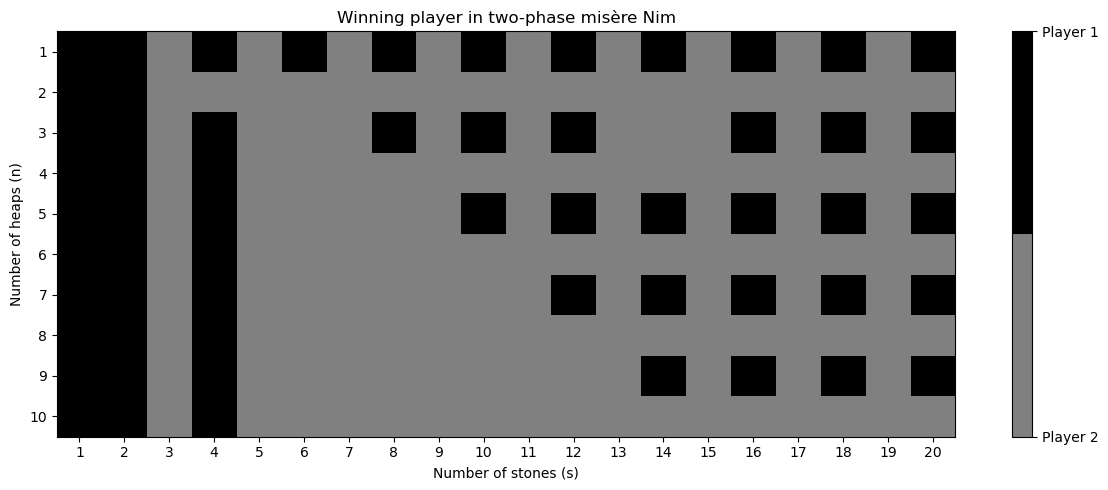

In [16]:
def heatmap(max_n, max_s):
    """
    Generate a heatmap showing which player has a winning strategy for various values of n and s.
    """
    results = np.zeros((max_n, max_s), dtype=int)

    for n in range(1, max_n + 1):
        for s in range(1, max_s + 1):
            winner_result = winner_Cannon(n, s)
            results[n - 1, s - 1] = 1 if winner_result == "Player 1" else 0 #1 if player 1 wins, 2 if player 2 wins

    cmap = ListedColormap(["grey", "black"]) #grey for player 2, black for player 1

    fig, ax = plt.subplots(figsize=(12, 5))
    im = ax.imshow(
        results,
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
        vmin=0,
        vmax=1
    )

    ax.set_xticks(range(max_s))
    ax.set_xticklabels(range(1, max_s + 1))

    ax.set_yticks(range(max_n))
    ax.set_yticklabels(range(1, max_n + 1))

    ax.set_xlabel("Number of stones (s)")
    ax.set_ylabel("Number of heaps (n)")
    ax.set_title("Winning player in two-phase misère Nim")

    cbar = plt.colorbar(im, ax=ax, ticks=[0, 1])
    cbar.ax.set_yticklabels(["Player 2", "Player 1"])

    plt.tight_layout()
    plt.show()
    
heatmap(10, 20)

Player 2 winning strategy for odd s test

In [19]:


counterexamples = []

for n in range(1, 11):
    for s in range(3, 31, 2):
        result = winner_Cannon(n, s)

        if result != "Player 2":
            counterexamples.append((n, s))

print("Counterexamples:", counterexamples)

Counterexamples: []
